In [14]:

import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [15]:

from pathlib import Path
import requests

Path("data/raw").mkdir(parents=True, exist_ok=True)

url = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/master/"
    "data/Telco-Customer-Churn.csv"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

dataset_path = "data/raw/Telco-Customer-Churn.csv"

with open(dataset_path, "wb") as f:
    f.write(response.content)

df = pd.read_csv(dataset_path)

print("Dataset downloaded!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset downloaded!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [16]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nBlank TotalCharges values:")
print(df["TotalCharges"].astype(str).str.strip().eq("").sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


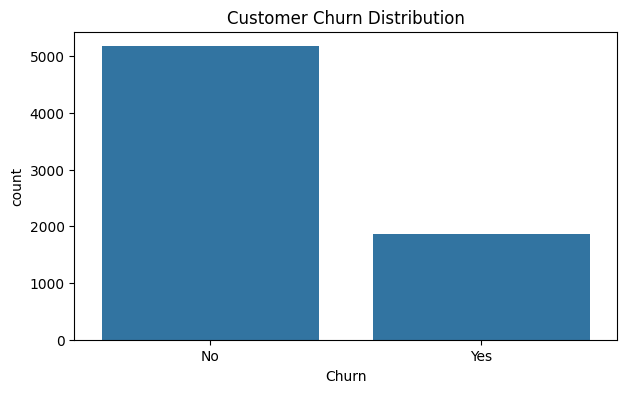

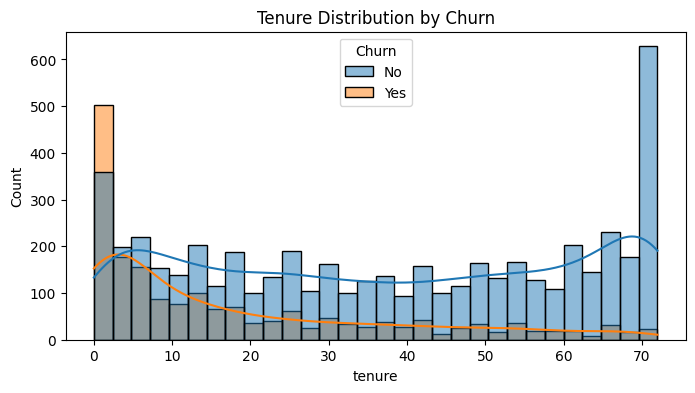

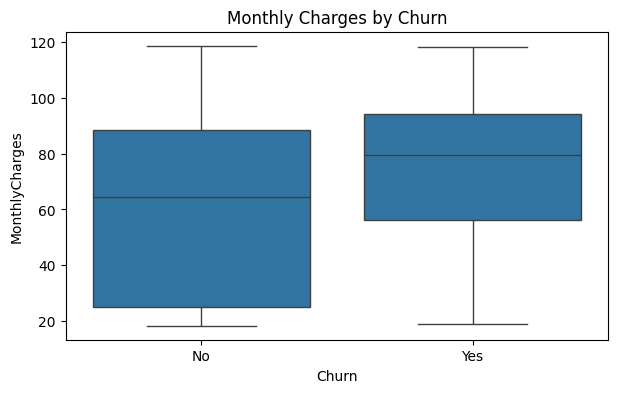

In [17]:

# Work on a separate copy for exploration
df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print(df_clean.isnull().sum())

# Churn distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

# Tenure distribution
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)
plt.title("Tenure Distribution by Churn")
plt.show()

# Monthly charges
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)
plt.title("Monthly Charges by Churn")
plt.show()


In [18]:

print(
    "TotalCharges median:",
    df_clean["TotalCharges"].median()
)


TotalCharges median: 1397.475


In [19]:

model_df = df.copy()

model_df["TotalCharges"] = pd.to_numeric(
    model_df["TotalCharges"],
    errors="coerce"
)

X = model_df.drop(
    columns=["Churn", "customerID"]
)

y = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features:", X.shape)
print("Target:", y.shape)
print(y.value_counts(dropna=False))


Features: (7043, 19)
Target: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [20]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

for name, labels in {
    "Training": y_train,
    "Validation": y_valid,
    "Test": y_test
}.items():
    print(
        name,
        "Records:", len(labels),
        "Churn rate:", round(labels.mean() * 100, 2), "%"
    )


Training Records: 4930 Churn rate: 26.53 %
Validation Records: 1056 Churn rate: 26.52 %
Test Records: 1057 Churn rate: 26.58 %


In [21]:

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [22]:

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [23]:

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_valid)

print(
    "Baseline F1:",
    f1_score(y_valid, baseline_predictions)
)

print(
    "Baseline Recall:",
    recall_score(y_valid, baseline_predictions)
)


Baseline F1: 0.0
Baseline Recall: 0.0


In [24]:

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training complete!")


Logistic Regression training complete!


In [25]:

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training complete!")


Random Forest training complete!


In [26]:

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_valid)
    probabilities = model.predict_proba(X_valid)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_valid, probabilities),
        "PR-AUC": average_precision_score(
            y_valid, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(4).sort_values(
        by="PR-AUC",
        ascending=False
    )
)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.7396,0.5055,0.8143,0.6238,0.8447,0.6308
1,Random Forest,0.7633,0.5408,0.7107,0.6142,0.8355,0.6141


In [27]:

best_model_name = results_df.sort_values(
    "PR-AUC",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Selected model:", best_model_name)


Selected model: Logistic Regression


In [28]:

valid_probabilities = best_model.predict_proba(
    X_valid
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_valid,
    valid_probabilities
)

# Select the threshold that maximizes validation F1
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Selected threshold:", round(best_threshold, 4))
print("Validation precision:", round(precision[best_index], 4))
print("Validation recall:", round(recall[best_index], 4))
print("Validation F1:", round(f1_values[best_index], 4))


Selected threshold: 0.5397
Validation precision: 0.522
Validation recall: 0.8036
Validation F1: 0.6329


In [29]:

test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Final Test Results")
print("------------------")

print("Accuracy:", accuracy_score(
    y_test, test_predictions
))

print("Precision:", precision_score(
    y_test, test_predictions, zero_division=0
))

print("Recall:", recall_score(
    y_test, test_predictions, zero_division=0
))

print("F1:", f1_score(
    y_test, test_predictions, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_test, test_probabilities
))

print("PR-AUC:", average_precision_score(
    y_test, test_probabilities
))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions, zero_division=0
))


Final Test Results
------------------
Accuracy: 0.7625354777672658
Precision: 0.5384615384615384
Recall: 0.7473309608540926
F1: 0.6259314456035767
ROC-AUC: 0.8446270682760392
PR-AUC: 0.6586153703128842

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83       776
           1       0.54      0.75      0.63       281

    accuracy                           0.76      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.76      0.77      1057



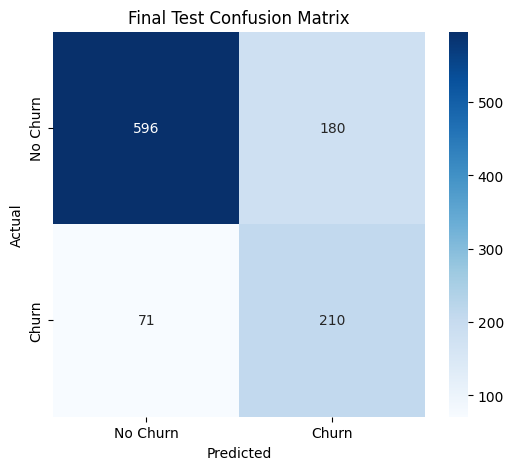

In [30]:

cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Test Confusion Matrix")
plt.show()


In [31]:

Path("artifacts").mkdir(exist_ok=True)

joblib.dump(
    best_model,
    "artifacts/churn_model.joblib"
)

metadata = {
    "model_name": best_model_name,
    "threshold": float(best_threshold),
    "target_mapping": {
        "No": 0,
        "Yes": 1
    },
    "features": X.columns.tolist()
}

with open("artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved!")


Model and metadata saved!


In [32]:

loaded_model = joblib.load(
    "artifacts/churn_model.joblib"
)

sample_customer = X_test.iloc[[0]]

sample_probability = loaded_model.predict_proba(
    sample_customer
)[:, 1][0]

sample_prediction = int(
    sample_probability >= best_threshold
)

print("Churn probability:", round(sample_probability, 4))
print(
    "Prediction:",
    "Churn" if sample_prediction == 1 else "No Churn"
)


Churn probability: 0.6793
Prediction: Churn


In [33]:

def predict_batch(input_df, model, threshold):
    required_columns = list(X.columns)

    missing_columns = [
        col for col in required_columns
        if col not in input_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    input_df = input_df[required_columns].copy()

    probabilities = model.predict_proba(input_df)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    output = input_df.copy()
    output["churn_probability"] = probabilities
    output["churn_prediction"] = predictions
    output["churn_label"] = np.where(
        predictions == 1,
        "Churn",
        "No Churn"
    )

    return output


In [34]:

sample_batch = X_test.head(100).copy()

batch_results = predict_batch(
    sample_batch,
    loaded_model,
    best_threshold
)

display(batch_results.head())

Path("outputs").mkdir(exist_ok=True)

batch_results.to_csv(
    "outputs/churn_predictions.csv",
    index=False
)

print("Batch predictions saved!")


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,churn_probability,churn_prediction,churn_label
1639,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,0.679332,1,Churn
3776,Male,0,Yes,No,43,Yes,No,DSL,No,No,...,Yes,No,One year,Yes,Mailed check,56.35,2391.15,0.225599,0,No Churn
805,Female,0,Yes,Yes,72,Yes,Yes,DSL,No,No,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),76.80,5468.45,0.078108,0,No Churn
2923,Male,0,No,No,54,Yes,No,Fiber optic,Yes,No,...,Yes,No,Month-to-month,No,Mailed check,89.80,4667.00,0.350526,0,No Churn
5392,Male,0,Yes,Yes,63,No,No phone service,DSL,No,Yes,...,No,No,Two year,No,Bank transfer (automatic),39.35,2395.05,0.020583,0,No Churn


Batch predictions saved!


In [35]:

benchmark_data = X_test.copy()

start_time = time.perf_counter()

benchmark_predictions = loaded_model.predict_proba(
    benchmark_data
)[:, 1]

end_time = time.perf_counter()

elapsed_seconds = end_time - start_time

records_per_second = (
    len(benchmark_data) / elapsed_seconds
)

print("Records processed:", len(benchmark_data))
print("Elapsed seconds:", round(elapsed_seconds, 4))
print("Records per second:", round(records_per_second, 2))


Records processed: 1057
Elapsed seconds: 0.0184
Records per second: 57571.09


In [36]:

# Test missing column
bad_input = X_test.head(1).drop(
    columns=[X_test.columns[0]]
)

try:
    predict_batch(
        bad_input,
        loaded_model,
        best_threshold
    )
except ValueError as error:
    print("Missing-column test passed:", error)

# Test unknown categorical values
unknown_input = X_test.head(1).copy()

for col in categorical_features:
    unknown_input[col] = "UNEXPECTED_CATEGORY"
    break

try:
    unknown_result = predict_batch(
        unknown_input,
        loaded_model,
        best_threshold
    )
    print("Unknown category test passed.")
except Exception as error:
    print("Unknown category test failed:", error)


Missing-column test passed: Missing required columns: ['gender']
Unknown category test passed.


In [37]:

missing_input = X_test.head(3).copy()

for col in numeric_features:
    missing_input[col] = np.nan

missing_result = predict_batch(
    missing_input,
    loaded_model,
    best_threshold
)

print(missing_result[
    ["churn_probability", "churn_prediction"]
])


      churn_probability  churn_prediction
1639           0.438954                 0
3776           0.261118                 0
805            0.213250                 0


In [41]:

def calculate_psi(reference, current, bins=10):
    reference = pd.Series(reference).dropna()
    current = pd.Series(current).dropna()

    if len(reference) == 0 or len(current) == 0:
        raise ValueError("Reference or current data is empty.")

    unique_values = reference.nunique()

    # For binary or low-cardinality features,
    # compare the frequency of each distinct value.
    if unique_values <= bins:
        categories = sorted(reference.unique())

        ref_pct = np.array([
            (reference == value).mean()
            for value in categories
        ])

        cur_pct = np.array([
            (current == value).mean()
            for value in categories
        ])

    else:
        # For continuous features, create quantile bins.
        edges = np.unique(
            np.quantile(
                reference,
                np.linspace(0, 1, bins + 1)
            )
        )

        edges[0] = -np.inf
        edges[-1] = np.inf

        ref_counts = np.histogram(reference, bins=edges)[0]
        cur_counts = np.histogram(current, bins=edges)[0]

        ref_pct = ref_counts / ref_counts.sum()
        cur_pct = cur_counts / cur_counts.sum()

    epsilon = 1e-6

    ref_pct = np.clip(ref_pct, epsilon, None)
    cur_pct = np.clip(cur_pct, epsilon, None)

    psi = np.sum(
        (cur_pct - ref_pct)
        * np.log(cur_pct / ref_pct)
    )

    return float(psi)


In [42]:

reference_data = X_train
current_data = X_test

drift_results = []

for feature in numeric_features:
    psi_value = calculate_psi(
        reference_data[feature],
        current_data[feature]
    )

    if psi_value < 0.10:
        status = "Low drift"
    elif psi_value < 0.25:
        status = "Moderate drift"
    else:
        status = "High drift"

    drift_results.append({
        "Feature": feature,
        "PSI": psi_value,
        "Status": status
    })

drift_df = pd.DataFrame(drift_results)

display(drift_df.round(4))


,Feature,PSI,Status
0,SeniorCitizen,0.0006,Low drift
1,tenure,0.0058,Low drift
2,MonthlyCharges,0.0160,Low drift
3,TotalCharges,0.0171,Low drift


In [43]:

import subprocess
import sys

requirements = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True
)

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created!")


requirements.txt created!


In [44]:

import sklearn
import pandas
import numpy
import matplotlib
import seaborn
import joblib
import requests
import pytest

packages = {
    "pandas": pandas.__version__,
    "numpy": numpy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__,
    "joblib": joblib.__version__,
    "requests": requests.__version__,
    "pytest": pytest.__version__
}

for package, version in packages.items():
    print(f"{package}=={version}")


pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
requests==2.32.4
pytest==8.4.2
